# Importing necessary libraries 

In [165]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from pathlib import Path
from sklearn.pipeline import Pipeline

# data preprocessing 

In [166]:
path=Path('ML_Model.ipynb').resolve().parent.parent
df=pd.read_csv(path/'data'/'raw_data.csv')
df=pd.DataFrame(df)

In [167]:
# categorical values ['gender', 'seniorcitizen', 'partner', 'dependents', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod']
# numeric feature ['tenure','monthlycharges','totalcharges']
df['totalcharges'] = pd.to_numeric(
    df['totalcharges'].astype(str).str.strip().replace('',np.nan),
    errors='coerce'
)
df['seniorcitizen']=df['seniorcitizen'].map({
    0:'No',
    1:'Yes'
})
df['churn']=df['churn'].map(
    {
        'Yes':1,
        'No':0
    }
)
categorical_features=['gender', 'seniorcitizen', 'partner', 'dependents', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod']
numeric_feature=['tenure','monthlycharges','totalcharges']

categorical_pipeline=Pipeline([
    ('Imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])
numeric_pipeline=Pipeline([
    ('inputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])

preprocessing=ColumnTransformer([
    ('cat',categorical_pipeline,categorical_features),
    ('num',numeric_pipeline,numeric_feature)
])
X=df.drop(['churn','customerid'],axis=1)
y=df['churn']
print(preprocessing.transformers)

[('cat', Pipeline(steps=[('Imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))]), ['gender', 'seniorcitizen', 'partner', 'dependents', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod']), ('num', Pipeline(steps=[('inputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())]), ['tenure', 'monthlycharges', 'totalcharges'])]


In [168]:
from lightgbm import LGBMClassifier
ml=Pipeline([
    ('preprocessing',preprocessing),
    ('model',LGBMClassifier(random_state=42, verbosity=-1, n_jobs=1,class_weight={0:1,1:2},max_depth=5, min_child_samples=40,num_leaves=31))
])


In [169]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,y,train_size=0.8,test_size=0.2,random_state=42,stratify=y)

In [170]:
ml.fit(X_train,Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','seniorcitizen','partner',...,'paymentmethod','monthlycharges', 'totalcharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='p

In [171]:
Y_pred = ml.predict(X_test)
Y_prob = ml.predict_proba(X_test)[:, 1]

In [172]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:", accuracy_score(Y_test, Y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(Y_test, Y_pred))
print("\nClassification Report:\n", classification_report(Y_test, Y_pred))
print("ROC-AUC:", roc_auc_score(Y_test, Y_prob))

Accuracy: 0.7743080198722498

Confusion Matrix:
 [[833 202]
 [116 258]]

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.80      0.84      1035
           1       0.56      0.69      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.77      0.78      1409

ROC-AUC: 0.8374977395437754


Transformed test shape: (1409, 46)
LightGBM model: <class 'lightgbm.sklearn.LGBMClassifier'>
SHAP values shape: (1409, 46)


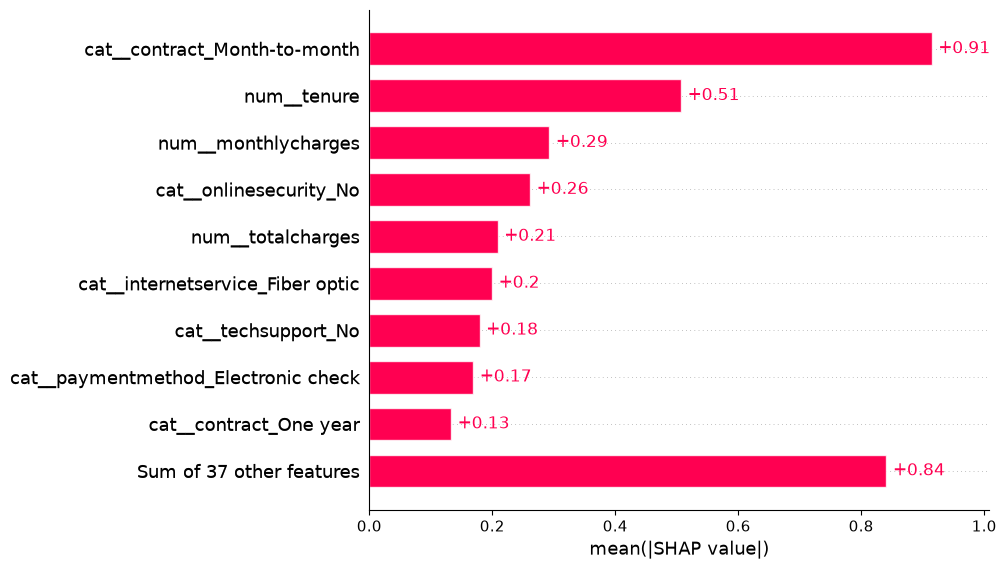

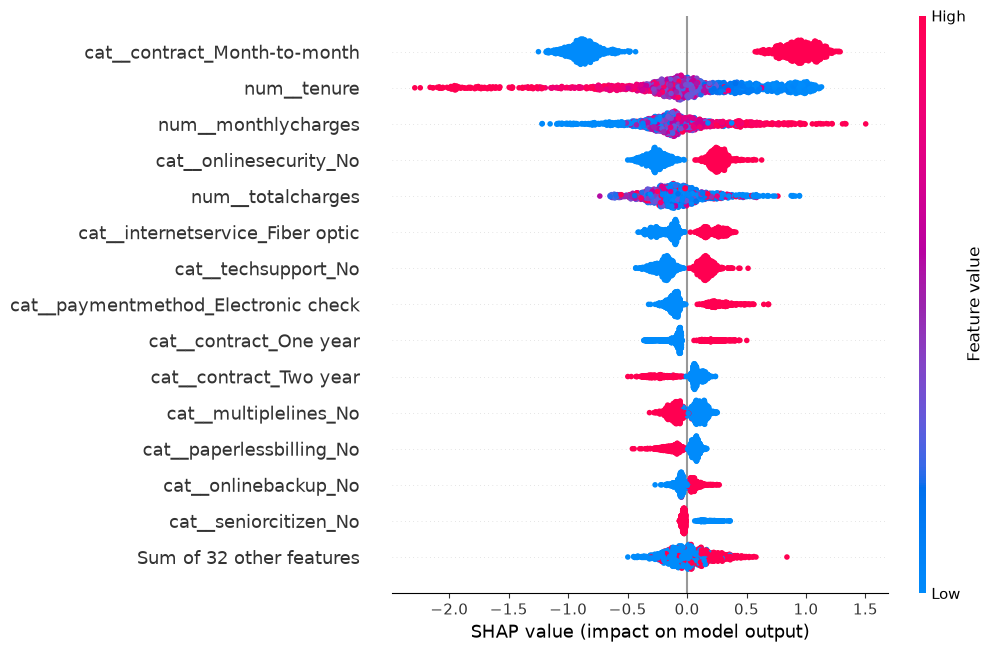

dict_keys(['preprocessing', 'model'])


In [ ]:
import shap
preprocessor = ml.named_steps["preprocessing"]
lgbm_model = ml.named_steps["model"]

X_test_transformed = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
X_test_transformed = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)
print("Transformed test shape:", X_test_transformed.shape)
print("LightGBM model:", type(lgbm_model))


explainer = shap.TreeExplainer(lgbm_model)

shap_values = explainer(X_test_transformed)
print("SHAP values shape:", shap_values.values.shape)
shap.plots.bar(shap_values)
shap.plots.beeswarm(shap_values, max_display=15)

ColumnTransformer(transformers=[('cat',
                                 Pipeline(steps=[('Imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['gender', 'seniorcitizen', 'partner',
                                  'dependents', 'phoneservice', 'multiplelines',
                                  'internetservice', 'onlinesecurity',
                                  'onlinebackup', 'deviceprotection',
                                  'techsupport', 'streamingtv',
                                  'streamingmovies', 'contract',
                                  'paperlessbilling', 'paymentmethod']),
                                ('num',
                                 Pipeline(steps=[('inputer',
                                                  Simple